# Воспроизводимость эксперимента

Перед будущим вычислительным запуском задаём **seed = 42** для `random`, NumPy и PyTorch, если он установлен. Дополнительно задаём seed CTranslate2: именно этот движок выполняет декодирование Faster-Whisper и использует собственный генератор случайных чисел. Выполнение ячейки с seed не запускает распознавание, RMS или VAD.

Seed старых CSV **не был зафиксирован**. Настройка 42 относится к новым экспериментам и не меняет уже сохранённые результаты. Для работы с ними используем CSV и metadata. Одинаковый seed не гарантирует побитовое совпадение на других версиях библиотек и оборудовании.

В `results/experiment_metadata.json` записаны версии Python и библиотек, ОС, CPU/GPU, SHA-256 видео, параметры методов и результаты статического анализа вариативности Whisper. [Seed CTranslate2](https://opennmt.net/CTranslate2/python/ctranslate2.set_random_seed.html).

In [1]:
import random
import importlib.util

import numpy as np
import ctranslate2

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
ctranslate2.set_random_seed(SEED)

seed_applied = {"random": True, "numpy": True, "ctranslate2": True, "torch": False}
if importlib.util.find_spec("torch") is not None:
    import torch
    torch.manual_seed(SEED)
    seed_applied["torch"] = True

print(f"Seed для будущих запусков: {SEED}")
print("Генераторы:", seed_applied)
if not seed_applied["torch"]:
    print("PyTorch не установлен: его seed пропущен.")

Seed для будущих запусков: 42
Генераторы: {'random': True, 'numpy': True, 'ctranslate2': True, 'torch': False}
PyTorch не установлен: его seed пропущен.


In [2]:
import json
from pathlib import Path

import pandas as pd

repro_results_dir = Path("results")
if not (repro_results_dir / "experiment_metadata.json").is_file():
    repro_results_dir = Path("backend") / "results"
repro_metadata = json.loads((repro_results_dir / "experiment_metadata.json").read_text(encoding="utf-8"))

print("ОС:", repro_metadata["environment"]["os"]["caption"])
print("CPU:", repro_metadata["environment"]["cpu"]["model"])
print("GPU:", repro_metadata["environment"]["gpu"][0]["model"])
print("SHA-256 видео:", repro_metadata["source"]["sha256"])
print("Seed сохранённых CSV:", repro_metadata["reproducibility"]["existing_csv_seed_status"])
print("Аргументов Whisper transcribe:", len(repro_metadata["methods"]["whisper"]["parameters"]["transcribe_call_arguments"]))

pd.DataFrame(
    {"package": package, "version": repro_metadata["versions"].get(package)}
    for package in ["python", "faster-whisper", "ctranslate2", "numpy", "pandas", "torch", "onnxruntime"]
)

ОС: Майкрософт Windows 11 Pro
CPU: AMD Ryzen 7 7800X3D 8-Core Processor
GPU: NVIDIA GeForce RTX 3070
SHA-256 видео: 77e46a42708d73daa9bff1351a509820cbf48c914310670489da4022b5fc554b
Seed сохранённых CSV: not recorded at generation time
Аргументов Whisper transcribe: 35


,package,version
0,python,3.11.9
1,faster-whisper,1.2.1
2,ctranslate2,4.8.2
3,numpy,2.4.6
4,pandas,3.0.6
5,torch,NaN
6,onnxruntime,1.29.0


### Почему Whisper мог выдать 165 и 328 сегментов

В обоих сохранённых сценариях код задаёт `small`, `cuda`, `float16`, русский язык и отключённый VAD. В metadata зафиксирован набор температур `[0, 0.2, 0.4, 0.6, 0.8, 1.0]`. В установленном коде `generate_with_fallback` при `compression_ratio > 2.4` или `avg_logprob < −1.0` возможен переход к следующей температуре. При температуре выше нуля включается **случайная выборка токенов**, а не beam search с исходной шириной 5.

Сгенерированные токены временных меток определяют разбиение на сегменты и продвижение по аудио. При `condition_on_previous_text=True` предыдущий текст влияет на следующие окна, поэтому изменения могут распространяться на продолжение записи. Незафиксированный seed CTranslate2 — правдоподобный источник различий. Seed Python, NumPy или PyTorch сам по себе не задаёт seed этого движка.

Это **гипотеза по коду**, а не доказанная причина конкретных запусков. В CSV нет температур по сегментам, вероятностей и логов fallback; полный результат запуска на 165 сегментов не сохранён. Версии текущего окружения совпадают с metadata зафиксированного запуска (`faster-whisper 1.2.1`, `ctranslate2 4.8.2`), но отдельного снимка версий старого запуска нет. Оснований утверждать, что причиной стало обновление библиотек, недостаточно.

Для воспроизведения текущих сравнений используются сохранённые CSV. При будущих вычислительных экспериментах seed-ячейка выполняется до создания модели; параметры и диагностические показатели каждого запуска следует сохранять отдельно.

# Исследование обнаружения неречевых фрагментов видео

## 1. Faster-Whisper: первичная оценка промежутков между сегментами речи

В этом эксперименте Faster-Whisper распознаёт русскую речь в `test_video.mp4` и возвращает текст с временными границами сегментов. По промежуткам между ними получим предварительную оценку участков без распознанной речи.

Используем модель `small`, GPU (`cuda`) и точность `float16`. Время обработки измеряем без загрузки модели, но с декодированием аудио и полным распознаванием. Скорость относительно реального времени — длительность записи, делённая на время обработки.

Здесь «пауза» означает положительный промежуток **между соседними сегментами Whisper**. Начало до первого сегмента, конец после последнего и паузы внутри сегментов в эту статистику не входят. Такой промежуток может содержать шум, музыку или речь, которую модель не распознала.

Выберите ядро из `backend/venv/Scripts/python.exe` и выполняйте ячейки сверху вниз. [Документация Faster-Whisper](https://github.com/SYSTRAN/faster-whisper#usage).

In [1]:
import os
import sys
import time
from pathlib import Path

import nvidia.cublas
import nvidia.cudnn
import pandas as pd
import matplotlib.pyplot as plt

# Сохраняем объекты, чтобы пути к CUDA DLL оставались подключены в ядре.
cublas_dll_directory = os.add_dll_directory(os.path.join(nvidia.cublas.__path__[0], "bin"))
cudnn_dll_directory = os.add_dll_directory(os.path.join(nvidia.cudnn.__path__[0], "bin"))

from faster_whisper import WhisperModel

%matplotlib inline

# Ядро может стартовать из backend или из корня videoeditor.
VIDEO_PATH = Path("test_video.mp4")
if not VIDEO_PATH.is_file():
    VIDEO_PATH = Path("backend") / "test_video.mp4"
VIDEO_PATH = VIDEO_PATH.resolve()
if not VIDEO_PATH.is_file():
    raise FileNotFoundError(f"Видео не найдено: {VIDEO_PATH}")

print("Python:", sys.executable)
print("Видео:", VIDEO_PATH)

Python: Z:\polikek 7\videoeditor\backend\venv\Scripts\python.exe
Видео: Z:\polikek 7\videoeditor\backend\test_video.mp4


Z:\polikek 7\videoeditor\backend\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
model_size = "small"
device = "cuda"
compute_type = "float16"

print("Загрузка модели...")
model = WhisperModel(model_size, device=device, compute_type=compute_type)
print("Модель загружена.")

Загрузка модели...


Модель загружена.


In [3]:
print("Начинаем распознавание...")
started_at = time.perf_counter()

segments, info = model.transcribe(str(VIDEO_PATH), language="ru", vad_filter=False)
# Распознавание завершается при обходе генератора, поэтому учитываем list() во времени.
segments = list(segments)

elapsed = time.perf_counter() - started_at
print("Распознавание завершено.")

Начинаем распознавание...


Распознавание завершено.


In [4]:
realtime = info.duration / elapsed

print(f"Длительность видео: {info.duration:.1f} сек.")
print(f"Время обработки: {elapsed:.1f} сек.")
print(f"Скорость: {realtime:.2f}x realtime")
print(f"Количество сегментов: {len(segments)}")

Длительность видео: 1429.0 сек.
Время обработки: 108.2 сек.
Скорость: 13.21x realtime
Количество сегментов: 165


In [5]:
speech_df = pd.DataFrame(
    [
        {
            "start": segment.start,
            "end": segment.end,
            "duration": segment.end - segment.start,
            "text": segment.text.strip(),
        }
        for segment in segments
    ],
    columns=["start", "end", "duration", "text"],
)

speech_df.head()

,start,end,duration,text
0,0.00,7.80,7.80,"Как бросить парнографию, просмотр грязных виде..."
1,7.80,17.76,9.96,"Других способов нету, поверьте. Будете ходить ..."
2,17.76,27.60,9.84,"Понимаете, это же отравляет душу, отчерстляет ..."
3,28.20,38.40,10.20,"Ау забилда. Понимаете, это единственный способ..."
4,38.40,48.80,10.40,Но самый мощный способ. Без этого вы будете хо...


In [6]:
# shift(-1) берёт начало следующего сегмента; для последнего получается NaN.
next_start = speech_df["start"].shift(-1)
speech_df["pause_after"] = (next_start - speech_df["end"]).clip(lower=0)

speech_df.head()

,start,end,duration,text,pause_after
0,0.00,7.80,7.80,"Как бросить парнографию, просмотр грязных виде...",0.000000e+00
1,7.80,17.76,9.96,"Других способов нету, поверьте. Будете ходить ...",0.000000e+00
2,17.76,27.60,9.84,"Понимаете, это же отравляет душу, отчерстляет ...",6.000000e-01
3,28.20,38.40,10.20,"Ау забилда. Понимаете, это единственный способ...",0.000000e+00
4,38.40,48.80,10.40,Но самый мощный способ. Без этого вы будете хо...,7.105427e-15


In [7]:
pause_mask = speech_df["pause_after"] > 0
pauses_df = pd.DataFrame(
    {
        "pause_start": speech_df.loc[pause_mask, "end"],
        "pause_end": next_start.loc[pause_mask],
        "duration": speech_df.loc[pause_mask, "pause_after"],
    }
).reset_index(drop=True)

pauses_df.head()

,pause_start,pause_end,duration
0,27.6,28.2,6.000000e-01
1,48.8,48.8,7.105427e-15
2,148.0,149.0,1.000000e+00
3,208.0,210.0,2.000000e+00
4,268.0,269.0,1.000000e+00


In [8]:
pause_durations = pauses_df["duration"]

print(f"Количество найденных пауз: {len(pauses_df)}")
if pauses_df.empty:
    print("Средняя, медианная и максимальная длительности: нет данных")
else:
    print(f"Средняя длительность: {pause_durations.mean():.3f} сек.")
    print(f"Медианная длительность: {pause_durations.median():.3f} сек.")
    print(f"Максимальная длительность: {pause_durations.max():.3f} сек.")

for threshold in [0.5, 1.0, 1.5, 2.0, 3.0]:
    count = (pause_durations >= threshold).sum()
    print(f"Пауз >= {threshold:.1f} сек.: {count}")

print(f"Суммарная длительность промежутков: {pause_durations.sum():.3f} сек.")

Количество найденных пауз: 19
Средняя длительность: 3.623 сек.
Медианная длительность: 1.000 сек.
Максимальная длительность: 25.000 сек.
Пауз >= 0.5 сек.: 17
Пауз >= 1.0 сек.: 15
Пауз >= 1.5 сек.: 6
Пауз >= 2.0 сек.: 6
Пауз >= 3.0 сек.: 5
Суммарная длительность промежутков: 68.840 сек.


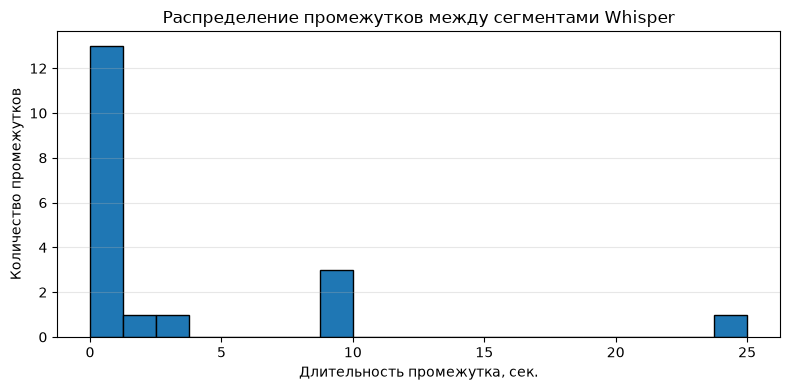

In [9]:
if pauses_df.empty:
    print("Положительных промежутков нет: гистограмму строить не из чего.")
else:
    plt.figure(figsize=(8, 4))
    plt.hist(pause_durations, bins=20, edgecolor="black")
    plt.title("Распределение промежутков между сегментами Whisper")
    plt.xlabel("Длительность промежутка, сек.")
    plt.ylabel("Количество промежутков")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

### Промежуточное заключение

Эксперимент позволяет получить первичную оценку промежутков без распознанной речи по временным сегментам Whisper. Численные результаты появляются в ячейках после реального запуска и зависят от видео и параметров модели.

Отсутствие распознанной речи **не гарантирует тишину или отсутствие речи**: модель может пропустить слова, а внутри промежутка могут оставаться другие звуки. Паузы внутри одного сегмента здесь также не обнаруживаются. Перед автоматическим удалением такие границы нужно проверять.

В дальнейшем эти результаты следует сравнить с методами анализа аудиосигнала и Voice Activity Detection (VAD).

## 2. RMS: обнаружение участков с низким уровнем сигнала

RMS (root mean square) — среднеквадратический уровень аудиосигнала. Это простой baseline: делим аудио на короткие окна, измеряем их уровень и считаем окна ниже порога кандидатами на тишину.

Для окна из $N$ отсчётов: $RMS = \sqrt{\frac{1}{N}\sum_{i=1}^{N}x_i^2}$. Переводим уровень в $dBFS = 20\log_{10}(RMS)$ относительно амплитуды полной шкалы 1. Аудио загружается как mono PCM, 16 кГц, с исходным уровнем громкости; нормализацию по пику не применяем. Окна по 30 мс не перекрываются. Последнее короткое окно учитывается по фактическим отсчётам.

Сравним пороги −50, −45, −40, −35 и −30 dBFS. Более высокий порог относит больше окон к тишине, но может захватить тихую речь. Соседние окна одной категории объединяем в интервалы; короткие провалы сохраняем без сглаживания. В отличие от таблицы Whisper, здесь учитываем также тишину в начале и конце аудио.

RMS оценивает энергию, поэтому участки выше порога — **предполагаемая речь**, которая может оказаться музыкой или шумом. Раздел можно выполнять отдельно, сверху вниз. Для загрузки используем уже установленный [декодер Faster-Whisper на PyAV](https://github.com/SYSTRAN/faster-whisper/blob/master/faster_whisper/audio.py); модель не загружается.

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from faster_whisper.audio import decode_audio

%matplotlib inline

rms_video_path = Path("test_video.mp4")
if not rms_video_path.is_file():
    rms_video_path = Path("backend") / "test_video.mp4"
rms_video_path = rms_video_path.resolve()
if not rms_video_path.is_file():
    raise FileNotFoundError(f"Видео не найдено: {rms_video_path}")

rms_sample_rate = 16000
rms_started_at = time.perf_counter()
rms_audio = decode_audio(str(rms_video_path), sampling_rate=rms_sample_rate)
if len(rms_audio) == 0:
    raise ValueError("Аудиодорожка пуста")
rms_audio_duration = len(rms_audio) / rms_sample_rate

print(f"Длительность аудио: {rms_audio_duration:.3f} сек.")
print(f"Частота дискретизации: {rms_sample_rate} Гц; каналов: 1")

Z:\polikek 7\videoeditor\backend\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Длительность аудио: 1428.956 сек.
Частота дискретизации: 16000 Гц; каналов: 1


In [2]:
rms_window_ms = 30
rms_window_samples = round(rms_sample_rate * rms_window_ms / 1000)
rms_rows = []

for sample_start in range(0, len(rms_audio), rms_window_samples):
    sample_end = min(sample_start + rms_window_samples, len(rms_audio))
    window = rms_audio[sample_start:sample_end]
    rms_value = np.sqrt(np.mean(window ** 2, dtype=np.float64))
    rms_rows.append(
        {
            "start": sample_start / rms_sample_rate,
            "end": sample_end / rms_sample_rate,
            "rms": rms_value,
        }
    )

rms_windows_df = pd.DataFrame(rms_rows, columns=["start", "end", "rms"])
# Нулевой RMS ограничиваем снизу только для защиты от log10(0).
rms_windows_df["dbfs"] = 20 * np.log10(rms_windows_df["rms"].clip(lower=1e-10))
rms_elapsed = time.perf_counter() - rms_started_at

print(f"Размер окна: {rms_window_ms} мс; количество окон: {len(rms_windows_df)}")
print(f"Загрузка аудио и расчёт RMS: {rms_elapsed:.2f} сек.")
rms_windows_df.head()

Размер окна: 30 мс; количество окон: 47632


Загрузка аудио и расчёт RMS: 1.40 сек.


,start,end,rms,dbfs
0,0.00,0.03,0.000000,-200.000000
1,0.03,0.06,0.014565,-36.733684
2,0.06,0.09,0.031965,-29.906609
3,0.09,0.12,0.011916,-38.477049
4,0.12,0.15,0.009333,-40.599178


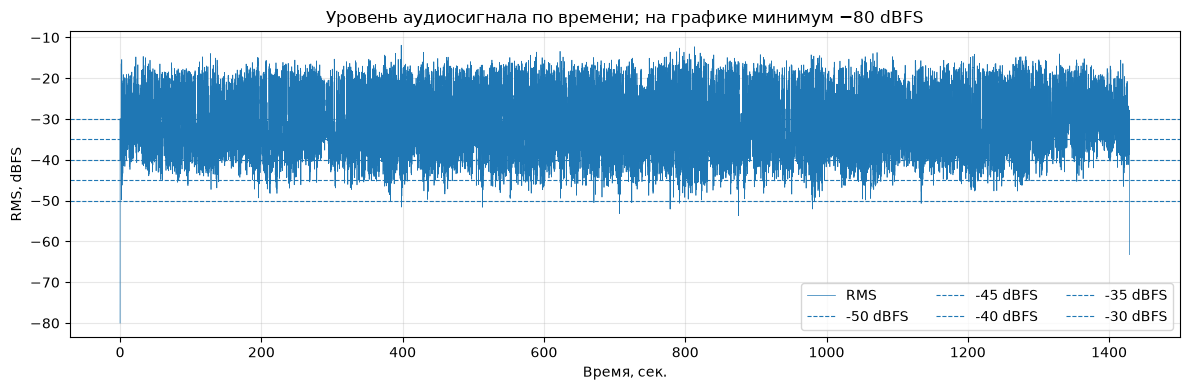

In [3]:
rms_thresholds_dbfs = [-50, -45, -40, -35, -30]

plt.figure(figsize=(12, 4))
# Ограничение -80 dBFS относится только к рисунку: исходные уровни сохраняются.
plt.plot(rms_windows_df["start"], rms_windows_df["dbfs"].clip(lower=-80), linewidth=0.5, label="RMS")
for threshold in rms_thresholds_dbfs:
    plt.axhline(threshold, linestyle="--", linewidth=0.8, label=f"{threshold} dBFS")
plt.title("Уровень аудиосигнала по времени; на графике минимум −80 dBFS")
plt.xlabel("Время, сек.")
plt.ylabel("RMS, dBFS")
plt.legend(loc="lower right", ncol=3)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [4]:
def rms_mask_to_intervals(windows_df, mask):
    """Объединяет соседние выбранные окна в интервалы start/end."""
    intervals = []
    interval_start = None
    interval_end = None

    for start, end, selected in zip(windows_df["start"], windows_df["end"], mask):
        if selected:
            if interval_start is None:
                interval_start = start
            interval_end = end
        elif interval_start is not None:
            intervals.append({"start": interval_start, "end": interval_end})
            interval_start = None

    # Завершаем интервал, если последнее окно также выбрано.
    if interval_start is not None:
        intervals.append({"start": interval_start, "end": interval_end})

    return pd.DataFrame(intervals, columns=["start", "end"])

In [5]:
rms_threshold_rows = []

for threshold in rms_thresholds_dbfs:
    silence_mask = rms_windows_df["dbfs"] < threshold
    silence_intervals = rms_mask_to_intervals(rms_windows_df, silence_mask)
    durations = silence_intervals["end"] - silence_intervals["start"]
    silence_total = durations.sum()
    rms_threshold_rows.append(
        {
            "threshold_dbfs": threshold,
            "pause_count": len(silence_intervals),
            "mean_pause_s": durations.mean(),
            "median_pause_s": durations.median(),
            "max_pause_s": durations.max(),
            "silence_total_s": silence_total,
            "silence_percent": 100 * silence_total / rms_audio_duration,
            "pauses_ge_0_5s": (durations >= 0.5).sum(),
        }
    )

rms_threshold_comparison_df = pd.DataFrame(rms_threshold_rows)
rms_threshold_comparison_df.round(3)

,threshold_dbfs,pause_count,mean_pause_s,median_pause_s,max_pause_s,silence_total_s,silence_percent,pauses_ge_0_5s
0,-50,17,0.042,0.03,0.12,0.716,0.050,0
1,-45,426,0.040,0.03,0.21,17.126,1.198,0
2,-40,2635,0.060,0.03,0.99,159.056,11.131,12
3,-35,4076,0.115,0.06,1.71,467.216,32.696,175
4,-30,4213,0.178,0.09,2.94,748.286,52.366,362


### Интервалы для рабочего порога

Таблица показывает чувствительность результата к порогу: сравниваем количество, длительности и долю тихих участков, а также число пауз от 0,5 секунды. Для подробного примера берём **−40 dBFS**, середину исследованного диапазона: это RMS менее 0,01 (1% полной шкалы). Это рабочая настройка для дальнейшего сравнения, а не доказанный оптимальный порог. Для оценки качества понадобится эталонная разметка.

Порог можно изменить в следующей ячейке и повторить расчёт интервалов и статистики. Окна строго ниже порога считаем тишиной, остальные — предполагаемой речью. Обе таблицы используют секунды и единые столбцы `start` / `end`; длительность интервала равна `end - start`.

In [6]:
rms_selected_threshold_dbfs = -40
rms_silence_mask = rms_windows_df["dbfs"] < rms_selected_threshold_dbfs

rms_silence_intervals = rms_mask_to_intervals(rms_windows_df, rms_silence_mask)
rms_speech_intervals = rms_mask_to_intervals(rms_windows_df, ~rms_silence_mask)

print(f"Порог: {rms_selected_threshold_dbfs} dBFS")
print(f"Интервалов предполагаемой речи: {len(rms_speech_intervals)}")
print(f"Интервалов тишины: {len(rms_silence_intervals)}")
display(rms_speech_intervals.head())
display(rms_silence_intervals.head())

Порог: -40 dBFS
Интервалов предполагаемой речи: 2634
Интервалов тишины: 2635


,start,end
0,0.03,0.12
1,0.15,0.18
2,0.21,1.71
3,1.80,1.98
4,2.13,2.64


,start,end
0,0.00,0.03
1,0.12,0.15
2,0.18,0.21
3,1.71,1.80
4,1.98,2.13


In [7]:
rms_pause_durations = rms_silence_intervals["end"] - rms_silence_intervals["start"]

print(f"Количество найденных пауз: {len(rms_silence_intervals)}")
if rms_silence_intervals.empty:
    print("Средняя, медианная и максимальная длительности: нет данных")
else:
    print(f"Средняя длительность: {rms_pause_durations.mean():.3f} сек.")
    print(f"Медианная длительность: {rms_pause_durations.median():.3f} сек.")
    print(f"Максимальная длительность: {rms_pause_durations.max():.3f} сек.")

print(f"Суммарная длительность пауз: {rms_pause_durations.sum():.3f} сек.")
print(f"Доля тишины: {100 * rms_pause_durations.sum() / rms_audio_duration:.2f}%")
print(f"Пауз >= 0.5 сек.: {(rms_pause_durations >= 0.5).sum()}")

Количество найденных пауз: 2635
Средняя длительность: 0.060 сек.
Медианная длительность: 0.030 сек.
Максимальная длительность: 0.990 сек.
Суммарная длительность пауз: 159.056 сек.
Доля тишины: 11.13%
Пауз >= 0.5 сек.: 12


### Промежуточное заключение по RMS

Эксперимент даёт интервалы низкого уровня сигнала и показывает, как их количество и длительности зависят от порога. Численные результаты формируются после запуска ячеек. Это описание поведения baseline, а не измерение точности обнаружения речи.

Шум и музыка выше порога могут считаться речью, а тихие слова ниже порога — тишиной. Без сглаживания короткие провалы уровня создают отдельные паузы; точность границ ограничена окном 30 мс. Поэтому полученные интервалы требуют проверки перед удалением.

`rms_speech_intervals` в формате `start` / `end` можно использовать для будущего сравнения с Whisper и VAD. Для корректного сравнения понадобится единая разметка и одинаковые правила учёта коротких пауз и границ записи. Здесь время отсчитывается от первого декодированного аудиоотсчёта; возможное смещение аудиодорожки относительно видео перед монтажом нужно проверять отдельно.

## 3. Silero VAD: обнаружение речевой активности

Silero VAD — нейросетевой детектор речевой активности. Он оценивает вероятность речи в аудио и формирует интервалы с учётом порогов и минимальных длительностей. Текст речи здесь не распознаётся.

Используем **Silero VAD v6 в формате ONNX**, уже поставляемый с `faster-whisper`, через функции `faster_whisper.vad`. Это отдельный запуск VAD, без модели Whisper. В установленной реализации ONNX Runtime выполняет модель на CPU с одним потоком вычислений. Аудио декодируется в mono, 16 кГц, как в RMS-разделе; шаг анализа — 512 отсчётов (32 мс).

Задаём рабочую конфигурацию явно: вероятность начала речи 0,5 и порог завершения 0,35; минимальные речь и пауза по 250 мс. Разные вероятностные пороги помогают не переключать состояние на каждом небольшом колебании. `speech_pad_ms=0` оставляет границы без расширения, а неограниченная максимальная длина речи исключает принудительное разбиение длинных интервалов. Эти настройки являются исходным вариантом эксперимента, а не результатом оптимизации.

Неречевые интервалы получаем как дополнение речевых на всей аудиодорожке, включая начало и конец. В статистике называем их «паузами» или «тишиной», но они могут содержать музыку, шум и пропущенную детектором речь. Обе таблицы используют `start` / `end` в секундах от начала декодированного аудио.

Раздел можно запускать отдельно, сверху вниз. [Silero VAD](https://github.com/snakers4/silero-vad) и [реализация в Faster-Whisper](https://github.com/SYSTRAN/faster-whisper/blob/master/faster_whisper/vad.py).

In [1]:
import time
from pathlib import Path
from dataclasses import asdict
from importlib.metadata import version

import pandas as pd
import matplotlib.pyplot as plt
from faster_whisper.audio import decode_audio
from faster_whisper.vad import VadOptions, get_speech_timestamps, get_vad_model

%matplotlib inline

silero_video_path = Path("test_video.mp4")
if not silero_video_path.is_file():
    silero_video_path = Path("backend") / "test_video.mp4"
silero_video_path = silero_video_path.resolve()
if not silero_video_path.is_file():
    raise FileNotFoundError(f"Видео не найдено: {silero_video_path}")

silero_sample_rate = 16000
silero_options = VadOptions(
    threshold=0.5,
    neg_threshold=0.35,
    min_speech_duration_ms=250,
    max_speech_duration_s=float("inf"),
    min_silence_duration_ms=250,
    speech_pad_ms=0,
)

print("Модель: Silero VAD v6 (ONNX, faster-whisper)")
print(f"faster-whisper: {version('faster-whisper')}; onnxruntime: {version('onnxruntime')}")
print(f"Аудио: mono, {silero_sample_rate} Гц; шаг: 512 отсчётов (32 мс)")
for name, value in asdict(silero_options).items():
    print(f"{name}: {value}")

silero_model_started_at = time.perf_counter()
silero_model = get_vad_model()
silero_model_load_elapsed = time.perf_counter() - silero_model_started_at
print("Исполнитель:", silero_model.session.get_providers())
print("Потоков ONNX Runtime:", silero_model.session.get_session_options().intra_op_num_threads)
print(f"Инициализация модели: {silero_model_load_elapsed:.3f} сек.")

Z:\polikek 7\videoeditor\backend\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Модель: Silero VAD v6 (ONNX, faster-whisper)
faster-whisper: 1.2.1; onnxruntime: 1.29.0
Аудио: mono, 16000 Гц; шаг: 512 отсчётов (32 мс)
threshold: 0.5
neg_threshold: 0.35
min_speech_duration_ms: 250
max_speech_duration_s: inf
min_silence_duration_ms: 250
speech_pad_ms: 0


Исполнитель: ['CPUExecutionProvider']
Потоков ONNX Runtime: 1
Инициализация модели: 0.313 сек.


In [2]:
# Модель уже загружена: время ниже включает декодирование и VAD, но не её инициализацию.
silero_processing_started_at = time.perf_counter()
silero_audio = decode_audio(str(silero_video_path), sampling_rate=silero_sample_rate)
if len(silero_audio) == 0:
    raise ValueError("Аудиодорожка пуста")
silero_decode_elapsed = time.perf_counter() - silero_processing_started_at
silero_audio_duration = len(silero_audio) / silero_sample_rate

silero_vad_started_at = time.perf_counter()
silero_speech_samples = get_speech_timestamps(
    silero_audio,
    vad_options=silero_options,
    sampling_rate=silero_sample_rate,
)
silero_vad_elapsed = time.perf_counter() - silero_vad_started_at
silero_processing_elapsed = time.perf_counter() - silero_processing_started_at
silero_realtime = silero_audio_duration / silero_processing_elapsed

print(f"Длительность аудио: {silero_audio_duration:.3f} сек.")
print(f"Декодирование: {silero_decode_elapsed:.3f} сек.")
print(f"Только VAD: {silero_vad_elapsed:.3f} сек.")
print(f"Полная обработка без загрузки модели: {silero_processing_elapsed:.3f} сек.")
print(f"Скорость полной обработки: {silero_realtime:.2f}x realtime")

Длительность аудио: 1428.956 сек.
Декодирование: 1.211 сек.
Только VAD: 1.986 сек.
Полная обработка без загрузки модели: 3.198 сек.
Скорость полной обработки: 446.87x realtime


In [3]:
# Дополнение считаем в отсчётах, чтобы точно сохранить границы аудио.
silero_silence_samples = []
silero_cursor = 0
for interval in silero_speech_samples:
    if interval["start"] > silero_cursor:
        silero_silence_samples.append({"start": silero_cursor, "end": interval["start"]})
    silero_cursor = interval["end"]
if silero_cursor < len(silero_audio):
    silero_silence_samples.append({"start": silero_cursor, "end": len(silero_audio)})

silero_speech_intervals = pd.DataFrame(silero_speech_samples, columns=["start", "end"]) / silero_sample_rate
silero_silence_intervals = pd.DataFrame(silero_silence_samples, columns=["start", "end"]) / silero_sample_rate

print("Речевые интервалы, сек.:")
display(silero_speech_intervals.head())
print("Неречевые интервалы, сек.:")
display(silero_silence_intervals.head())

Речевые интервалы, сек.:


,start,end
0,1.600,3.840
1,4.256,5.824
2,6.112,7.648
3,8.544,10.624
4,11.232,13.696


Неречевые интервалы, сек.:


,start,end
0,0.000,1.600
1,3.840,4.256
2,5.824,6.112
3,7.648,8.544
4,10.624,11.232


In [4]:
silero_speech_durations = silero_speech_intervals["end"] - silero_speech_intervals["start"]
silero_pause_durations = silero_silence_intervals["end"] - silero_silence_intervals["start"]
silero_speech_total = silero_speech_durations.sum()
silero_silence_total = silero_pause_durations.sum()
silero_speech_percent = 100 * silero_speech_total / silero_audio_duration
silero_silence_percent = 100 * silero_silence_total / silero_audio_duration

print(f"Количество speech-интервалов: {len(silero_speech_intervals)}")
print(f"Количество silence-интервалов: {len(silero_silence_intervals)}")
print(f"Суммарная речь: {silero_speech_total:.3f} сек. ({silero_speech_percent:.2f}%)")
print(f"Суммарная тишина: {silero_silence_total:.3f} сек. ({silero_silence_percent:.2f}%)")

if silero_silence_intervals.empty:
    print("Средняя, медианная и максимальная пауза: нет данных")
else:
    print(f"Средняя пауза: {silero_pause_durations.mean():.3f} сек.")
    print(f"Медианная пауза: {silero_pause_durations.median():.3f} сек.")
    print(f"Максимальная пауза: {silero_pause_durations.max():.3f} сек.")

for threshold in [0.5, 1.0, 1.5, 2.0, 3.0]:
    print(f"Пауз >= {threshold:.1f} сек.: {(silero_pause_durations >= threshold).sum()}")

Количество speech-интервалов: 337
Количество silence-интервалов: 338
Суммарная речь: 1157.248 сек. (80.99%)
Суммарная тишина: 271.708 сек. (19.01%)
Средняя пауза: 0.804 сек.
Медианная пауза: 0.672 сек.
Максимальная пауза: 3.840 сек.
Пауз >= 0.5 сек.: 242
Пауз >= 1.0 сек.: 82
Пауз >= 1.5 сек.: 26
Пауз >= 2.0 сек.: 11
Пауз >= 3.0 сек.: 1


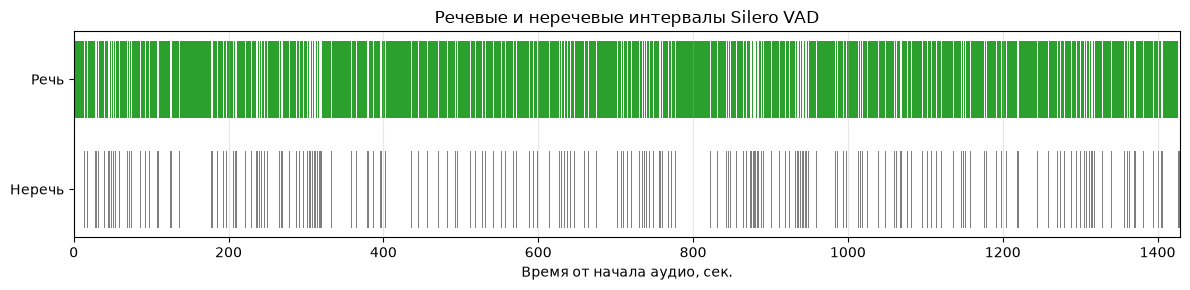

In [5]:
silero_speech_bars = list(zip(silero_speech_intervals["start"], silero_speech_durations))
silero_silence_bars = list(zip(silero_silence_intervals["start"], silero_pause_durations))

plt.figure(figsize=(12, 3))
plt.broken_barh(silero_speech_bars, (1, 0.7), facecolors="tab:green")
plt.broken_barh(silero_silence_bars, (0, 0.7), facecolors="tab:gray")
plt.xlim(0, silero_audio_duration)
plt.yticks([0.35, 1.35], ["Неречь", "Речь"])
plt.title("Речевые и неречевые интервалы Silero VAD")
plt.xlabel("Время от начала аудио, сек.")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### Промежуточное заключение по Silero VAD

Этот эксперимент получает речевые интервалы нейросетевым детектором и неречевые интервалы как их дополнение. Таблицы `silero_speech_intervals` и `silero_silence_intervals` представлены в едином формате `start` / `end`; результаты и время работы появляются после запуска.

Количество и длительности пауз зависят от порогов, минимальных длительностей и расширения границ. При текущих настройках короткие участки речи отбрасываются, короткие провалы могут оставаться внутри речевого интервала, а границы не расширяются. Поэтому статистика описывает работу конкретной конфигурации детектора.

Неречевой интервал не гарантирует физическую тишину, а речевой — безошибочное обнаружение речи. Для выводов о качестве нужны прослушивание и эталонная разметка. Перед будущим сравнением и монтажом также нужно проверить временное смещение аудио относительно видео. На этом этапе сохраняем интервалы и описательную статистику без оценки F1 и удаления фрагментов.

## 4. Сравнение речевых интервалов на первых 120 секундах

Сопоставим результаты Whisper, RMS при **−40 dBFS** и Silero VAD на одном временном участке. Используем зафиксированные CSV и JSON из `backend/results/`. После перезапуска ядра выполняйте только сравнительные ячейки этого раздела: первая Code-ячейка загружает результаты с диска. Запуск предыдущих вычислительных разделов для сравнения не требуется.

Для Whisper считаем речью полную длительность распознанных сегментов, для RMS — окна не ниже −40 dBFS, для Silero — интервалы VAD с ранее заданными параметрами. Эти определения различаются: пауза внутри сегмента Whisper здесь входит в его речевой интервал.

Обрезаем интервалы по границам участка и объединяем пересечения и соприкосновения, чтобы исключить двойной подсчёт. Неречь для каждого метода — дополнение до полной длительности участка, включая его начало и конец. На графике цветные полосы показывают решение «речь», серый фон — «неречь». Это сравнение решений методов без эталонной разметки и оценки качества.

In [22]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline

results_dir = Path("results")
if not (results_dir / "experiment_metadata.json").is_file():
    results_dir = Path("backend") / "results"
results_dir = results_dir.resolve()
saved_results = json.loads((results_dir / "experiment_metadata.json").read_text(encoding="utf-8"))
result_tables = {
    filename: pd.read_csv(
        results_dir / filename,
        encoding="utf-8",
        float_precision="round_trip",
        keep_default_na=False,
        na_values={"pause_after": [""]},
    )
    for filename in saved_results["csv_files"]
}

comparison_start = 0.0
comparison_end = min(120.0, saved_results["source"]["audio_duration_seconds"])
comparison_duration = comparison_end - comparison_start
assert saved_results["methods"]["rms"]["parameters"]["threshold_dbfs"] == -40


def comparison_clip_and_merge(intervals_df, start, end):
    """Обрезает интервалы и объединяет пересекающиеся или соприкасающиеся."""
    clipped = intervals_df[["start", "end"]].copy()
    clipped["start"] = clipped["start"].clip(lower=start)
    clipped["end"] = clipped["end"].clip(upper=end)
    clipped = clipped[clipped["end"] > clipped["start"]].sort_values("start")
    merged = []

    for interval_start, interval_end in clipped.itertuples(index=False, name=None):
        # Допуск устраняет только погрешность чисел, а не реальные короткие паузы.
        if merged and interval_start <= merged[-1]["end"] + 1e-9:
            merged[-1]["end"] = max(merged[-1]["end"], interval_end)
        else:
            merged.append({"start": interval_start, "end": interval_end})

    return pd.DataFrame(merged, columns=["start", "end"])

comparison_source_intervals = {
    "Whisper": result_tables["whisper_speech_intervals.csv"],
    "RMS": result_tables["rms_speech_intervals.csv"],
    "Silero VAD": result_tables["silero_speech_intervals.csv"],
}
comparison_speech_intervals = {
    method: comparison_clip_and_merge(intervals, comparison_start, comparison_end)
    for method, intervals in comparison_source_intervals.items()
}
print(f"Участок сравнения: {comparison_start:.1f}–{comparison_end:.1f} сек.; RMS: −40 dBFS")

Участок сравнения: 0.0–120.0 сек.; RMS: −40 dBFS


In [23]:
comparison_rows = []
for method, intervals in comparison_speech_intervals.items():
    speech_seconds = (intervals["end"] - intervals["start"]).sum()
    non_speech_seconds = comparison_duration - speech_seconds
    comparison_rows.append(
        {
            "method": method,
            "speech_intervals": len(intervals),
            "speech_s": speech_seconds,
            "non_speech_s": non_speech_seconds,
            "speech_percent": 100 * speech_seconds / comparison_duration,
            "non_speech_percent": 100 * non_speech_seconds / comparison_duration,
        }
    )

comparison_summary_df = pd.DataFrame(comparison_rows)
comparison_summary_df.round(3)

,method,speech_intervals,speech_s,non_speech_s,speech_percent,non_speech_percent
0,Whisper,2,119.400,0.600,99.500,0.500
1,RMS,186,111.630,8.370,93.025,6.975
2,Silero VAD,36,89.632,30.368,74.693,25.307


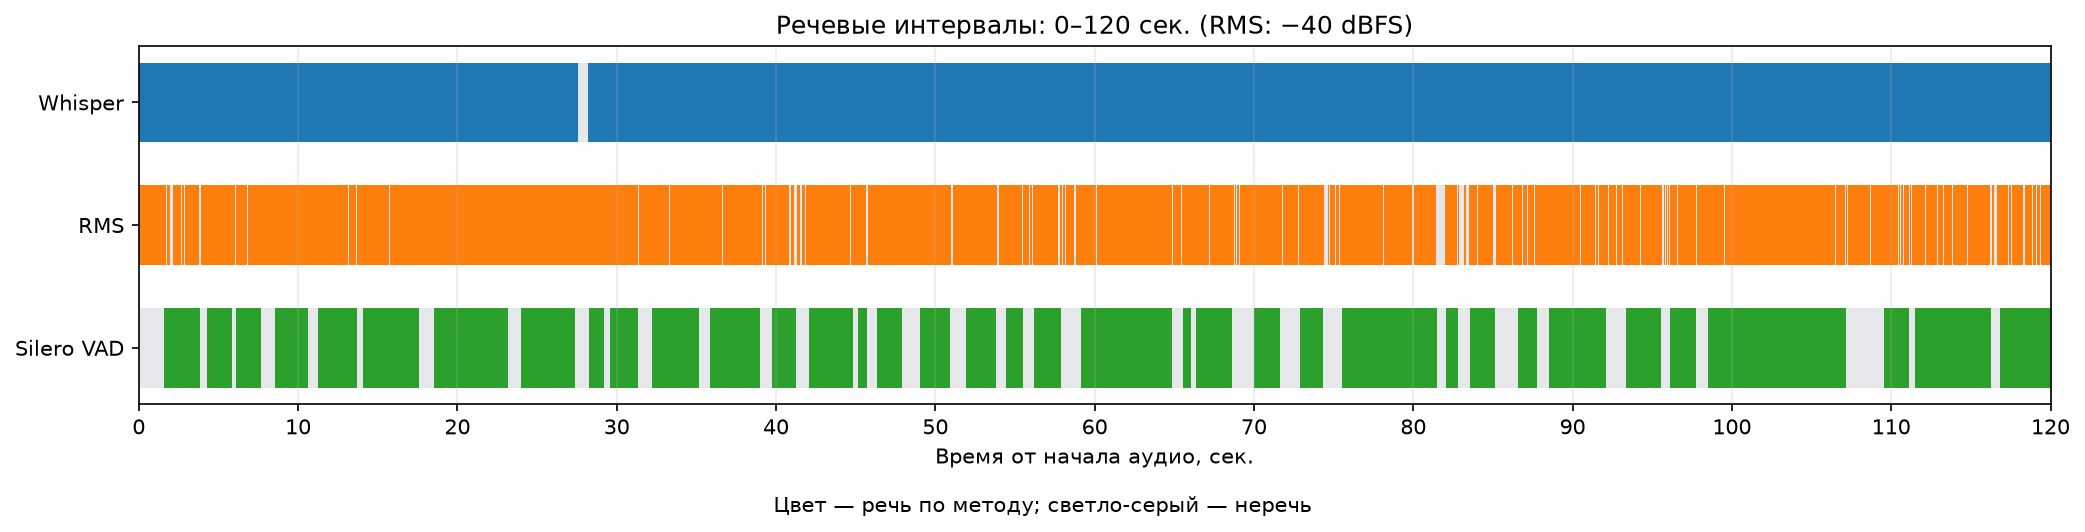

In [24]:
comparison_colors = {"Whisper": "tab:blue", "RMS": "tab:orange", "Silero VAD": "tab:green"}
comparison_methods = list(comparison_speech_intervals)

fig, ax = plt.subplots(figsize=(14, 3.5), dpi=150)
for row, method in zip([2, 1, 0], comparison_methods):
    intervals = comparison_speech_intervals[method]
    speech_bars = list(zip(intervals["start"], intervals["end"] - intervals["start"]))
    ax.broken_barh([(comparison_start, comparison_duration)], (row, 0.65), facecolors="#E5E7EB", edgecolors="none")
    ax.broken_barh(speech_bars, (row, 0.65), facecolors=comparison_colors[method], edgecolors="none")

ax.set_yticks([2.325, 1.325, 0.325], comparison_methods)
ax.set_xlim(comparison_start, comparison_end)
ax.set_xticks(np.arange(comparison_start, comparison_end + 1e-9, 10))
ax.set_xlabel("Время от начала аудио, сек.")
ax.set_title(f"Речевые интервалы: {comparison_start:.0f}–{comparison_end:.0f} сек. (RMS: −40 dBFS)")
ax.grid(axis="x", alpha=0.25)
fig.text(0.5, 0.01, "Цвет — речь по методу; светло-серый — неречь", ha="center")
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

### Наблюдения по сравнению

На первых 120 секундах Whisper отмечает почти весь участок как речь, оставляя только промежуток 27,6–28,2 секунды. RMS при −40 dBFS даёт много коротких провалов; Silero VAD выделяет более продолжительные неречевые участки и меньшую суммарную длительность речи. Это наблюдения для текущего видео и настроек.

Например, на участках **0,210–1,600** и **17,568–18,560 секунды** Whisper и RMS показывают речь, а Silero VAD — неречь. На **1,710–1,800 секунды** Whisper и Silero показывают речь, а RMS — неречь. Такие места удобно проверять прослушиванием.

Крупные сегменты Whisper могут включать внутренние паузы; RMS реагирует на уровень сигнала, а Silero VAD — на речевую активность с заданными порогами и минимальными длительностями. Большее или меньшее покрытие речи само по себе не определяет качество: вывод о том, какой метод лучше, требует эталонной разметки.

## 5. Зафиксированные результаты экспериментов

Полные таблицы находятся в `backend/results/`: `whisper_segments.csv` и по две таблицы `speech_intervals` / `silence_intervals` для Whisper, RMS и Silero. Временные границы хранятся в секундах как `start` / `end`, без округления при экспорте. В Whisper-сегментах также сохранены `duration`, `text` и `pause_after`.

`experiment_metadata.json` содержит параметры, версии библиотек, длительность и контрольную сумму исходного видео, времена обработки, статистику, сравнение первых 120 секунд и контрольные суммы CSV. Неречевые интервалы в CSV покрывают дополнение речи на всей аудиодорожке, включая начало и конец; прежняя статистика Whisper между сегментами записана отдельно.

До экспорта полные таблицы не сохранялись. Поэтому CSV фиксируют один новый запуск с прежними параметрами; старый вывод notebook оставлен как исторический результат и указан в JSON отдельно. Для дальнейших сравнений используйте `result_tables` и `saved_results`, которые сравнительная ячейка загружает из файлов. Следующая ячейка проверяет эти файлы без запуска моделей.

In [4]:
import hashlib

saved_file_rows = []
for filename, description in saved_results["csv_files"].items():
    table = result_tables[filename]
    digest = hashlib.sha256((results_dir / filename).read_bytes()).hexdigest()
    assert digest == description["sha256"], f"Изменён файл: {filename}"
    assert len(table) == description["rows"]
    assert table.columns.tolist() == description["columns"]
    saved_file_rows.append({"file": filename, "rows": len(table), "sha256_ok": True})

print("CSV загружены; число строк, столбцы и контрольные суммы совпадают с JSON.")
pd.DataFrame(saved_file_rows)

CSV загружены; число строк, столбцы и контрольные суммы совпадают с JSON.


,file,rows,sha256_ok
0,whisper_segments.csv,328,True
1,whisper_speech_intervals.csv,34,True
2,whisper_silence_intervals.csv,34,True
3,rms_speech_intervals.csv,2634,True
4,rms_silence_intervals.csv,2635,True
5,silero_speech_intervals.csv,337,True
6,silero_silence_intervals.csv,338,True


## 6. Ground Truth: выбор фрагментов для ручной разметки

На этом этапе выбираем **пять непересекающихся фрагментов по 60 секунд** из разных частей видео. Это список участков для будущего прослушивания и ручной разметки, а не готовый Ground Truth. Истинные границы речи пока не задаём, видео не обрезаем.

Следующие три Code-ячейки работают самостоятельно после перезапуска ядра: они читают только сохранённые CSV и JSON из `results/`. Запускать предыдущие вычислительные разделы Whisper, RMS и Silero не требуется. RMS используется при ранее сохранённом пороге **−40 dBFS**.

Рассматриваем окна длительностью 60 секунд с шагом 10 секунд. По середине окна относим их к одной из пяти равных частей полной записи. В каждой части выбираем свой диагностический случай: небольшое расхождение; крупные промежутки без распознанной речи Whisper; близкая суммарная неречь RMS и Silero; длинная пауза Silero при сплошной речи Whisper; почти непрерывная речь по RMS в конце записи.

Неречь каждого метода считаем по его `silence_intervals.csv`, обрезая интервалы по границам окна. **Попарное расхождение** — время, когда один метод считает момент речью, а другой неречью (симметрическая разность интервалов). **Общее расхождение** — время, когда хотя бы один из трёх методов отличается от остальных; его процент считаем от 60 секунд. Для трёх бинарных решений это половина суммы трёх попарных расхождений. Расчёт ведём по точным границам CSV, без дискретизации времени; округление используется только при выводе.


In [1]:
import hashlib
import json
import math
from pathlib import Path

import pandas as pd
from IPython.display import display

gt_results_dir = Path("results")
if not (gt_results_dir / "experiment_metadata.json").is_file():
    gt_results_dir = Path("backend") / "results"
gt_results_dir = gt_results_dir.resolve()
gt_metadata_path = gt_results_dir / "experiment_metadata.json"
gt_metadata = json.loads(gt_metadata_path.read_text(encoding="utf-8"))
gt_video_duration = gt_metadata["source"]["audio_duration_seconds"]
assert gt_metadata["interval_convention"] == "[start, end)"
assert gt_metadata["methods"]["rms"]["parameters"]["threshold_dbfs"] == -40

gt_silence_intervals = {}
gt_source_hashes = {
    gt_metadata_path: hashlib.sha256(gt_metadata_path.read_bytes()).hexdigest()
}
for method in ["whisper", "rms", "silero"]:
    filename = f"{method}_silence_intervals.csv"
    path = gt_results_dir / filename
    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    assert digest == gt_metadata["csv_files"][filename]["sha256"], filename
    gt_source_hashes[path] = digest
    table = pd.read_csv(path, float_precision="round_trip")
    assert table.columns.tolist() == ["start", "end"]
    intervals = list(table.itertuples(index=False, name=None))
    previous_end = 0.0
    for start, end in intervals:
        assert math.isfinite(start) and math.isfinite(end)
        assert 0 <= start < end <= gt_video_duration + 1e-9
        assert start >= previous_end - 1e-9
        previous_end = end
    gt_silence_intervals[method] = intervals


def gt_clip_intervals(intervals, start, end):
    return [
        (max(start, a), min(end, b))
        for a, b in intervals if a < end and b > start
    ]


def gt_intersection_seconds(left, right):
    """Длительность пересечения двух упорядоченных наборов интервалов."""
    i = j = 0
    total = 0.0
    while i < len(left) and j < len(right):
        total += max(0.0, min(left[i][1], right[j][1]) - max(left[i][0], right[j][0]))
        if left[i][1] <= right[j][1]:
            i += 1
        else:
            j += 1
    return total


def gt_window_metrics(start, end):
    clipped = {
        method: gt_clip_intervals(intervals, start, end)
        for method, intervals in gt_silence_intervals.items()
    }
    row = {"start": float(start), "end": float(end), "duration": float(end - start)}
    for method, intervals in clipped.items():
        durations = [b - a for a, b in intervals]
        row[f"{method}_non_speech_s"] = sum(durations, 0.0)
        row[f"{method}_pause_count"] = len(durations)
        row[f"{method}_max_pause_s"] = max(durations, default=0.0)
    pairwise = []
    for left, right in [("whisper", "rms"), ("whisper", "silero"), ("rms", "silero")]:
        difference = (
            row[f"{left}_non_speech_s"] + row[f"{right}_non_speech_s"]
            - 2 * gt_intersection_seconds(clipped[left], clipped[right])
        )
        row[f"{left}_{right}_disagreement_s"] = max(0.0, difference)
        pairwise.append(max(0.0, difference))
    row["disagreement_s"] = sum(pairwise) / 2
    row["disagreement_percent"] = 100 * row["disagreement_s"] / row["duration"]
    return row


print(f"Загружены сохранённые интервалы; длительность аудио: {gt_video_duration:.3f} с.")


Загружены сохранённые интервалы; длительность аудио: 1428.956 с.


In [2]:
gt_window_seconds = 60
gt_step_seconds = 10
gt_candidate_rows = []
for start in range(0, int(gt_video_duration - gt_window_seconds) + 1, gt_step_seconds):
    end = start + gt_window_seconds
    row = gt_window_metrics(start, end)
    row["zone"] = min(5, int(((start + end) / 2) / gt_video_duration * 5) + 1)
    row["rms_silero_total_gap_s"] = abs(row["rms_non_speech_s"] - row["silero_non_speech_s"])
    gt_candidate_rows.append(row)
gt_candidates = pd.DataFrame(gt_candidate_rows)


def gt_zone_candidates(zone):
    return gt_candidates[gt_candidates["zone"] == zone]


# Разные критерии дают и спокойный участок, и сложные случаи для проверки.
gt_beginning = gt_zone_candidates(1).nsmallest(1, "disagreement_s")
gt_whisper_gap = gt_zone_candidates(2).sort_values(
    ["whisper_non_speech_s", "disagreement_s", "start"], ascending=[False, False, True]
).head(1)
gt_similar_totals = gt_zone_candidates(3).nsmallest(1, "rms_silero_total_gap_s")

gt_longest_silero_pause = max(gt_silence_intervals["silero"], key=lambda interval: interval[1] - interval[0])
gt_zone_four = gt_zone_candidates(4)
gt_long_pause_candidates = gt_zone_four[
    (gt_zone_four["start"] <= gt_longest_silero_pause[0])
    & (gt_zone_four["end"] >= gt_longest_silero_pause[1])
    & (gt_zone_four["whisper_non_speech_s"] < 1e-9)
]
assert not gt_long_pause_candidates.empty
gt_long_pause = gt_long_pause_candidates.sort_values(
    ["silero_non_speech_s", "start"], ascending=[False, True]
).head(1)
gt_ending = gt_zone_candidates(5).nsmallest(1, "rms_non_speech_s")

gt_selected_metrics = pd.concat(
    [gt_beginning, gt_whisper_gap, gt_similar_totals, gt_long_pause, gt_ending],
    ignore_index=True,
).drop(columns=["zone", "rms_silero_total_gap_s"])
gt_profiles = [
    "Малое расхождение в начале", "Крупные промежутки Whisper", "Близкие суммы, разные границы",
    "Длинная пауза Silero", "Почти сплошная речь RMS в конце",
]
gt_reasons = [
    f"Начало записи: минимальное общее расхождение среди окон первой части. Silero выделяет {int(gt_selected_metrics.loc[0, 'silero_pause_count'])} пауз; самая длинная — {gt_selected_metrics.loc[0, 'silero_max_pause_s']:.3f} с. Участок для проверки относительно согласованных решений.",
    "Вторая часть записи: максимальная суммарная неречь Whisper; при равенстве выбран участок с большим расхождением. В него входят промежутки Whisper 318–327 и 332–357 с, которые предстоит проверить прослушиванием.",
    f"Середина записи: наиболее близкая суммарная неречь RMS и Silero среди окон третьей части, но их временные решения различаются на {gt_selected_metrics.loc[2, 'rms_silero_disagreement_s']:.3f} с. RMS даёт {int(gt_selected_metrics.loc[2, 'rms_pause_count'])} коротких промежутков, Silero — {int(gt_selected_metrics.loc[2, 'silero_pause_count'])} пауз.",
    f"Четвёртая часть: целиком включает самый длинный неречевой интервал Silero {gt_longest_silero_pause[0]:.3f}–{gt_longest_silero_pause[1]:.3f} с ({gt_longest_silero_pause[1]-gt_longest_silero_pause[0]:.3f} с). Whisper считает всё окно речью. Среди таких окон выбрана максимальная суммарная неречь Silero.",
    f"Конец записи: минимальная неречь RMS среди окон пятой части. При этом Silero выделяет {int(gt_selected_metrics.loc[4, 'silero_pause_count'])} пауз; максимальная — {gt_selected_metrics.loc[4, 'silero_max_pause_s']:.3f} с. Проверяем расхождение уровня сигнала и VAD.",
]

ground_truth_segments = gt_selected_metrics.copy()
ground_truth_segments.insert(0, "segment_id", [f"segment_{i:02d}" for i in range(1, 6)])
ground_truth_segments.insert(4, "selection_profile", gt_profiles)
ground_truth_segments.insert(5, "reason", gt_reasons)
for method in ["whisper", "rms", "silero"]:
    ground_truth_segments[f"{method}_pause_count"] = ground_truth_segments[f"{method}_pause_count"].astype(int)

print(f"Рассмотрено {len(gt_candidates)} окон; выбрано 5 разных участков, всего 300 секунд.")
gt_summary_columns = [
    "segment_id", "start", "end", "whisper_non_speech_s", "rms_non_speech_s",
    "silero_non_speech_s", "disagreement_s", "disagreement_percent",
]
display(ground_truth_segments[gt_summary_columns].round(3))
print("Попарное временное расхождение, секунды:")
display(ground_truth_segments[[
    "segment_id", "whisper_rms_disagreement_s", "whisper_silero_disagreement_s", "rms_silero_disagreement_s"
]].round(3))
for row in ground_truth_segments.itertuples(index=False):
    print(f"\n{row.segment_id}: {row.start:.0f}–{row.end:.0f} с. {row.reason}")


Рассмотрено 137 окон; выбрано 5 разных участков, всего 300 секунд.


,segment_id,start,end,whisper_non_speech_s,rms_non_speech_s,silero_non_speech_s,disagreement_s,disagreement_percent
0,segment_01,130.0,190.0,1.0,3.09,3.904,6.524,10.873
1,segment_02,300.0,360.0,34.0,6.18,16.576,43.934,73.223
2,segment_03,680.0,740.0,3.0,10.10,10.208,16.502,27.503
3,segment_04,850.0,910.0,0.0,8.22,16.960,19.602,32.670
4,segment_05,1360.0,1420.0,0.0,0.85,13.696,14.062,23.437


Попарное временное расхождение, секунды:


,segment_id,whisper_rms_disagreement_s,whisper_silero_disagreement_s,rms_silero_disagreement_s
0,segment_01,3.85,4.200,4.998
1,segment_02,33.16,38.192,16.516
2,segment_03,11.64,8.880,12.484
3,segment_04,8.22,16.960,14.024
4,segment_05,0.85,13.696,13.578



segment_01: 130–190 с. Начало записи: минимальное общее расхождение среди окон первой части. Silero выделяет 6 пауз; самая длинная — 1.216 с. Участок для проверки относительно согласованных решений.

segment_02: 300–360 с. Вторая часть записи: максимальная суммарная неречь Whisper; при равенстве выбран участок с большим расхождением. В него входят промежутки Whisper 318–327 и 332–357 с, которые предстоит проверить прослушиванием.

segment_03: 680–740 с. Середина записи: наиболее близкая суммарная неречь RMS и Silero среди окон третьей части, но их временные решения различаются на 12.484 с. RMS даёт 164 коротких промежутков, Silero — 16 пауз.

segment_04: 850–910 с. Четвёртая часть: целиком включает самый длинный неречевой интервал Silero 877.568–881.408 с (3.840 с). Whisper считает всё окно речью. Среди таких окон выбрана максимальная суммарная неречь Silero.

segment_05: 1360–1420 с. Конец записи: минимальная неречь RMS среди окон пятой части. При этом Silero выделяет 18 пауз; максим

In [3]:
assert len(ground_truth_segments) == 5
assert (ground_truth_segments["duration"] == 60).all()
assert (ground_truth_segments["start"] >= 0).all()
assert (ground_truth_segments["end"] <= gt_video_duration).all()
assert (ground_truth_segments["start"].iloc[1:].to_numpy() >= ground_truth_segments["end"].iloc[:-1].to_numpy()).all()
assert ground_truth_segments["disagreement_s"].between(0, 60).all()

gt_output_path = gt_results_dir / "ground_truth_segments.csv"
if not gt_output_path.exists():
    ground_truth_segments.to_csv(gt_output_path, index=False, encoding="utf-8")
gt_reloaded = pd.read_csv(gt_output_path, encoding="utf-8", float_precision="round_trip", keep_default_na=False)
pd.testing.assert_frame_equal(ground_truth_segments, gt_reloaded, check_exact=True)

for path, digest in gt_source_hashes.items():
    assert hashlib.sha256(path.read_bytes()).hexdigest() == digest, f"Изменён исходный файл: {path.name}"
print(f"Список фрагментов сохранён: {gt_output_path}")
print("Повторная загрузка CSV совпадает точно. Исходные CSV и metadata не изменены.")
print("Это только список фрагментов: эталонные speech/silence интервалы ещё не размечены.")


Список фрагментов сохранён: Z:\polikek 7\videoeditor\backend\results\ground_truth_segments.csv
Повторная загрузка CSV совпадает точно. Исходные CSV и metadata не изменены.
Это только список фрагментов: эталонные speech/silence интервалы ещё не размечены.


### Что подготовлено для Ground Truth

В `ground_truth_segments.csv` сохранены границы пяти фрагментов, причины выбора, длительности неречи по методам, попарные и общие расхождения, количество и максимальная длительность пауз внутри каждого окна. `start` / `end` — абсолютные секунды от начала аудио; на границе окна пауза учитывается только своей попавшей в окно частью.

Это целенаправленный отбор разных диагностических случаев, включая относительно согласованный участок. Он не является случайной выборкой для несмещённой оценки всей записи. До ручного прослушивания нельзя утверждать, что промежутки, отмеченные методами, действительно являются неречью, или выбирать лучший метод. Следующий этап — согласовать правила ручной разметки и обозначить истинные интервалы речи внутри этих пяти фрагментов; сейчас разметка не создаётся.
